## Fréchet pitfalls. Flip, Clip, Parametrise.

When calculating the discrete Frechet metric, we try to find the smallest length (length of the longest segment) of any coupling between two nodes of a polyline. Ideally, all our centrelines would begin at the same start point and finish at the same end point. But it is not the case for the hydraulic lines. The discrete frechet metric would be dominated by this discrepancy. 

Another thing to bear in mind is the order of parametrisation of our polylines.

In [1]:
from os import chdir, path
thepath = path.abspath("../base")
chdir(thepath)

In [8]:
import yaml
import numpy as np
from frechet_dist import frdist
from scipy.interpolate import interp1d
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from utils import parametrise_ct

In [3]:
plt.rcParams["font.family"] = "Arial"

We choose first an epsilon: this is the average segment length we wish to retain at the end of the reparametrisation of the polygonal curve. To make sure that the discrete fréchet metric calculated is close to the actual fréchet distance, we precompute the metric on the unrefined polygonal lines, then choose epsilon so that $\epsilon << \delta_{DF}$.  For each segment in the sequence, we calculate its length $l$, and work out in how many subsegments $r$ it should be divided.

$r = \lceil l / \epsilon \rceil$

We then refine the centreline by adding equally spaced nodes on each linear segment.

In [6]:
with open(f"../notebooks/plot_kwargs.yaml", "r") as f: 
    p = yaml.safe_load(f)
    f.close()

skeleton_kwargs = p["skeleton_kwargs"]
node_kwargs = p["node_kwargs"]
ct_kwargs = p["ct_kwargs"]
ct_1_kwargs = p["ct1_kwargs"]
ct_2_kwargs = p["ct2_kwargs"]
mesh_kwargs = p["mesh_kwargs"]
start_kwargs = p["start_kwargs"]
end_kwargs = p["end_kwargs"]

In [9]:
P = np.array([[1, 0],
              [2, 0],
              [3, 0],
              [4, 0],
              [5, 0]])
Q = np.array([[1, 1],
              [2, 1],
              [3, 1],
              [4, 1],
              [5, 1]])

couple_1 = [[0,0],[0,1],[0,2], [0,3],[1,3],[2,3],[3,3],[4,4]]
couple_2 = [[0,4],[1,3],[1,2],[2,2],[2,1],[3,0], [4,0]]
couple_3 = [[0,0],[1,1], [2,2], [3,3], [4,4]]

In [10]:
couple_1_str = ""
for s,e in couple_1:
    couple_1_str += f"$(u_{{{s}}},v_{{{e}}})$,"

couple_2_str = ""
for s,e in couple_2:
    couple_2_str += f"$(u_{{{s}}},v_{{{4-e}}})$,"

couple_3_str = ""
for s,e in couple_3:
    couple_3_str += f"$(u_{{{s}}},v_{{{e}}})$,"


## What is a coupling ??

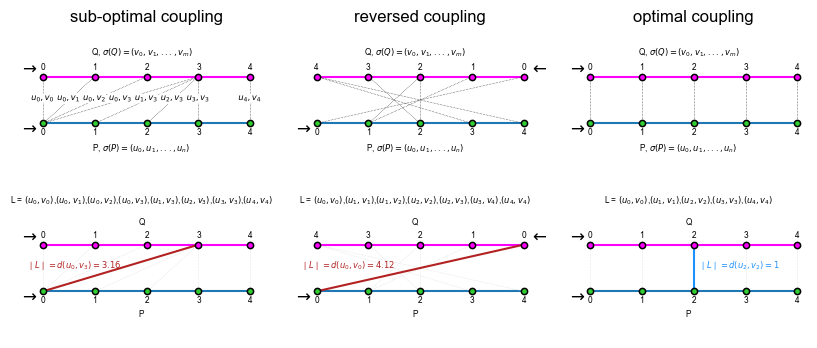

In [12]:
fig, axes = plt.subplots(2, 3, figsize = (10, 4))

ax = axes[0, 0]
ax.scatter(*P.T, **start_kwargs)
ax.plot(*P.T, color = "C0")
ax.scatter(*Q.T, **end_kwargs)
ax.plot(*Q.T, color = "fuchsia")

# number the p nodes
# number the q nodes. 
for i, (x,y) in enumerate(Q):
    ax.text(x, y+0.1, i, fontsize=6, va="bottom", ha="center")

for i, (x,y) in enumerate(P):
    ax.text(x, y-0.1, i, fontsize=6, va="top", ha="center")

for link in couple_1:
    s, e = link
    ax.plot(*np.vstack([P[s], Q[e]]).T,  ls = "dotted", color = "k", lw=.4)
    centre = (P[s] + Q[e]) / 2

    ax.text(*centre, f"$u_{{{s}}},v_{{{e}}}$", color="k", 
            fontsize=6, 
            ha="center", 
            path_effects=[pe.withStroke(linewidth=4, foreground="white")])

ax.text(0.9, 1.1, f"$\\rightarrow$", fontsize=12, ha="right")
ax.text(0.9, -0.1, f"$\\rightarrow$", fontsize=12, ha="right", va= "center")

ax = axes[1, 0]
ax.scatter(*P.T, **start_kwargs)
ax.plot(*P.T, color = "C0")
ax.scatter(*Q.T, **end_kwargs)
ax.plot(*Q.T, color = "fuchsia")
s, e = couple_1[3]
ax.plot(*np.vstack([P[s], Q[e]]).T, color="firebrick", ls = "-", zorder = 10)

# number the p nodes
# number the q nodes. 
for i, (x,y) in enumerate(Q):
    ax.text(x, y+0.1, i, fontsize=6, va="bottom", ha="center")

for i, (x,y) in enumerate(P):
    ax.text(x, y-0.1, i, fontsize=6, va="top", ha="center")

for link in couple_1:
    s, e = link
    ax.plot(*np.vstack([P[s], Q[e]]).T,  ls = "dotted", color = "lightgrey", lw=.4)

d = np.linalg.norm(P[0] - Q[3])

## annotate the infemum link length. 
ax.text(0.7, 0.5, f"$\\mid L\\mid =d (u_{{0}}, v_{{3}})  = {d:.2f}$", color="firebrick", fontsize=6, ha="left")
ax.text(0.9, 1.1, f"$\\rightarrow$", fontsize=12, ha="right")
ax.text(0.9, -0.1, f"$\\rightarrow$", fontsize=12, ha="right", va= "center")

ax = axes[0, 1]
ax.scatter(*P.T, **start_kwargs)
ax.plot(*P.T, color = "C0")
ax.scatter(*Q.T, **end_kwargs)
ax.plot(*Q.T, color = "fuchsia")

for link in couple_2:
    s, e = link
    ax.plot(*np.vstack([P[s], Q[e]]).T, ls = "dotted", color = "k", lw=.4)

# number the p nodes
# number the q nodes. 
for i, (x,y) in enumerate(Q[::-1]):
    ax.text(x, y+0.1, i, fontsize=6, va="bottom", ha="center")

for i, (x,y) in enumerate(P):
    ax.text(x, y-0.1, i, fontsize=6, va="top", ha="center")
ax.text(5.1, 1.1, f"$\\leftarrow$", fontsize=12, ha="left")
ax.text(0.9, -0.1, f"$\\rightarrow$", fontsize=12, ha="right", va= "center")


ax = axes[1, 1]
ax.scatter(*P.T, **start_kwargs)
ax.plot(*P.T, color = "C0")
ax.scatter(*Q.T, **end_kwargs)
ax.plot(*Q.T, color = "fuchsia")

s, e = couple_2[0]
ax.plot(*np.vstack([P[s], Q[e]]).T, color="firebrick", ls = "-", zorder = 10)

for link in couple_2:
    s, e = link
    ax.plot(*np.vstack([P[s], Q[e]]).T, ls = "dotted", color = "lightgrey", lw=.4)

# number the p nodes
# number the q nodes. 
for i, (x,y) in enumerate(Q[::-1]):
    ax.text(x, y+0.1, i, fontsize=6, va="bottom", ha="center")

for i, (x,y) in enumerate(P):
    ax.text(x, y-0.1, i, fontsize=6, va="top", ha="center")

d = np.linalg.norm(P[0] - Q[-1])
## annotate the infemum link length. 
ax.text(0.7, 0.5, f"$\\mid L\\mid =d (u_{{0}}, v_{{0}}) = {d:.2f}$", color="firebrick", fontsize=6, ha="left")
ax.text(5.1, 1.1, f"$\\leftarrow$", fontsize=12, ha="left")
ax.text(0.9, -0.1, f"$\\rightarrow$", fontsize=12, ha="right", va= "center")


ax = axes[0, 2]
ax.scatter(*P.T, **start_kwargs)
ax.plot(*P.T, color = "C0")
ax.scatter(*Q.T, **end_kwargs)
ax.plot(*Q.T, color = "fuchsia")

for link in couple_3:
    s, e = link
    ax.plot(*np.vstack([P[s], Q[e]]).T,ls = "dotted", color = "k", lw=.4)

# number the p nodes
# number the q nodes. 
for i, (x,y) in enumerate(Q):
    ax.text(x, y+0.1, i, fontsize=6, va="bottom", ha="center")

for i, (x,y) in enumerate(P):
    ax.text(x, y-0.1, i, fontsize=6, va="top", ha="center")


for ax, label, coupling_str in zip(axes[0], ("sub-optimal", "reversed", "optimal"), (couple_1_str, couple_2_str, couple_3_str)):
    ax.set_title(f"{label} coupling")

    ax.text(2.9,1.4,"Q, $\\sigma (Q) = (v_{0}, v_{1}, ..., v_{m})$", va="bottom", ha="center", fontsize=6)
    ax.text(2.9,-0.4,"P, $\\sigma (P) = (u_{0}, u_{1}, ..., u_{n})$", va="top", ha="center", fontsize= 6)
    ax.text(2.9, -1.5, f"L = {coupling_str[:-1]}", va="top", ha="center", fontsize=6)
    ax.set_ylim(-1, 2)
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ["bottom", "top", "left", "right"]:
        ax.spines[spine].set_visible(False)

ax.text(0.9, 1.1, f"$\\rightarrow$", fontsize=12, ha="right")
ax.text(0.9, -0.1, f"$\\rightarrow$", fontsize=12, ha="right", va= "center")

ax = axes[1, 2]
ax.scatter(*P.T, **start_kwargs)
ax.plot(*P.T, color = "C0")
ax.scatter(*Q.T, **end_kwargs)
ax.plot(*Q.T, color = "fuchsia")

s, e = couple_3[2]
ax.plot(*np.vstack([P[s], Q[e]]).T, color="dodgerblue", ls = "-", zorder = 10)
for link in couple_3:
    s, e = link
    ax.plot(*np.vstack([P[s], Q[e]]).T,ls = "dotted", color = "lightgrey", lw=.4)

# number the p nodes
# number the q nodes. 
for i, (x,y) in enumerate(Q):
    ax.text(x, y+0.1, i, fontsize=6, va="bottom", ha="center")

for i, (x,y) in enumerate(P):
    ax.text(x, y-0.1, i, fontsize=6, va="top", ha="center")

## annotate the infemum link length. 
ax.text(3.1, 0.5, "$\\mid L \\mid =d (u_{{2}}, v_{{2}})  = 1$", color="dodgerblue", fontsize=6, ha="left")
ax.text(0.9, 1.1, f"$\\rightarrow$", fontsize=12, ha="right")
ax.text(0.9, -0.1, f"$\\rightarrow$", fontsize=12, ha="right", va= "center")

for ax, label in zip(axes[1], ("sub-optimal", "reversed", "optimal")):
    ax.text(2.9,1.4,"Q", va="bottom", ha="center", fontsize=6)
    ax.text(2.9,-0.4,"P", va="top", ha="center", fontsize=6)

    ax.set_ylim(-1, 2)
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ["bottom", "top", "left", "right"]:
        ax.spines[spine].set_visible(False)
    ax.set_facecolor("None")
    
#plt.savefig("../temp/figures/couplings.png", dpi = 300)
#plt.savefig("../temp/figures/couplings.pdf")
plt.show()

In [13]:
frdist(P, Q)

np.float64(1.0)

Now we show an example of trimming the longer of the two paths. 

In [14]:
P = np.array([[1.75, 0.25],
              [3, 0.25],
              [4.25, 0.25]])
Q = np.array([[1, 1],
              [2, 1],
              [3, 1],
              [4, 1],
              [5, 1]])


couple_1 =  [[0,0],[0,1], [1,2], [2,3], [2, 4]]
couple_2 = [[0,0],[1,1], [2,2]]

0.7905694150420949
27 27


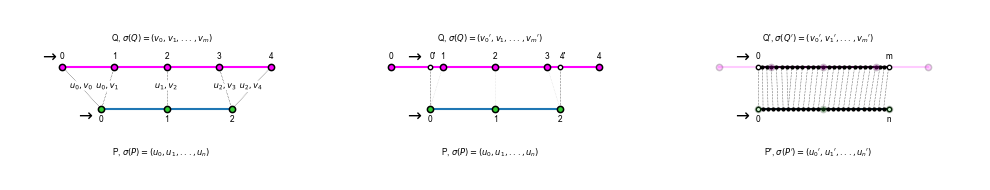

In [23]:
fig, axes = plt.subplots(1, 3, figsize = (10, 2))

ax = axes[0]
ax.scatter(*P.T, **start_kwargs)
ax.plot(*P.T, color = "C0")
ax.scatter(*Q.T, **end_kwargs)
ax.plot(*Q.T, color = "fuchsia")


# number the p nodes
# number the q nodes. 
for i, (x,y) in enumerate(Q):
    ax.text(x, y+0.1, i, fontsize=6, va="bottom", ha="center")

for i, (x,y) in enumerate(P):
    ax.text(x, y-0.1, i, fontsize=6, va="top", ha="center")

for link in couple_1:
    s, e = link
    ax.plot(*np.vstack([P[s], Q[e]]).T,  ls = "dotted", color = "k", lw=.4)
    centre = (P[s] + Q[e]) / 2

    ax.text(*centre, f"$u_{{{s}}},v_{{{e}}}$", color="k", 
            fontsize=6, 
            ha="center", 
            path_effects=[pe.withStroke(linewidth=4, foreground="white")])
ax.text(2.9,1.4,"Q, $\\sigma (Q) = (v_{0}, v_{1}, ..., v_{m})$", va="bottom", ha="center", fontsize=6)
ax.text(2.9,-0.4,"P, $\\sigma (P) = (u_{0}, u_{1}, ..., u_{n})$", va="top", ha="center", fontsize= 6)

ax.text(0.9, 1.1, f"$\\rightarrow$", fontsize=12, ha="right")
ax.text(1.6, 0.15, f"$\\rightarrow$", fontsize=12, ha="right", va= "center")

ax = axes[1]
ax.scatter(*P.T, **start_kwargs)
ax.plot(*P.T, color = "C0")
ax.scatter(*Q.T, **end_kwargs)
ax.plot(*Q.T, color = "fuchsia")


# number the p nodes
# number the q nodes. 
for i, (x,y) in enumerate(Q):
    ax.text(x, y+0.1, i, fontsize=6, va="bottom", ha="center")

for i, (x,y) in enumerate(P):
    ax.text(x, y-0.1, i, fontsize=6, va="top", ha="center")



# projection of a point on a segment.
n = (Q[1] - Q[0]) / np.linalg.norm(Q[1] - Q[0])
q = (P[0] - Q[0])
qprime = np.dot(n, q)*n
sprime = Q[0]+qprime

n = (Q[-2] - Q[-1]) / np.linalg.norm(Q[-2] - Q[-1])
q = (P[-1] - Q[-1])
qprime = np.dot(n, q)*n
eprime = Q[-1]+qprime

for k, link in enumerate(couple_1):
    s, e = link
    if k == 0:
        ax.plot(*np.vstack([P[0], sprime]).T, ls= "dotted", color = "k", lw=.4)
    elif k == len(couple_1) -1:
        ax.plot(*np.vstack([P[-1], eprime]).T, ls= "dotted", color = "k", lw=.4)
    else:
        ax.plot(*np.vstack([P[s], Q[e]]).T,  ls = "dotted", color = "lightgrey",lw=.4)
    centre = (P[s] + Q[e]) / 2


ax.scatter(*sprime, zorder =20, color = "white", s= 10, edgecolors="k")
ax.scatter(*eprime, zorder =20, color = "white", s= 10, edgecolors="k")
ax.text(sprime[0],sprime[1]+0.1, "0'", fontsize = 6, va="bottom")
ax.text(eprime[0],eprime[1]+0.1,"4'", fontsize = 6, va="bottom")
ax.text(2.9,1.4,"Q, $\\sigma (Q) = ({v_{0}}', v_{1}, ..., {v_{m}}')$", va="bottom", ha="center", fontsize=6)
ax.text(2.9,-0.4,"P, $\\sigma (P) = (u_{0}, u_{1}, ..., u_{n})$", va="top", ha="center", fontsize= 6)
ax.text(1.6, 1.1, f"$\\rightarrow$", fontsize=12, ha="right")
ax.text(1.6, 0.15, f"$\\rightarrow$", fontsize=12, ha="right", va= "center")



ax = axes[2]

Qprime = np.vstack([sprime, Q[1:-1], eprime])
print(frdist(P, Qprime))


Pnew = parametrise_ct(P, eps=0.1)


Qnew = parametrise_ct(Qprime, eps= 0.1)
print(len(Qnew), len(Pnew))


ax.scatter(*Pnew.T, s= 4, color = "k", zorder = 20)
ax.plot(*Pnew.T, color = "k")
ax.scatter(*Qnew.T, s= 4, color = "k", zorder= 20)
ax.plot(*Qnew.T, color = "k")
ax.scatter(*Q[:, [0,-1]].T, **end_kwargs, alpha = 0.2)
ax.scatter(*P[:, [0,-1]].T, **start_kwargs,alpha = 0.2)
ax.plot(*P.T, color = "C0", alpha = 0.2)
ax.plot(*Q.T, color = "fuchsia", alpha = 0.2)

ax.scatter(*sprime, zorder =20, color = "white", s= 10, edgecolors="k")
ax.scatter(*eprime, zorder =20, color = "white", s= 10, edgecolors="k")
ax.scatter(*P[0], zorder =20, color = "white", s= 10, edgecolors="k")
ax.scatter(*P[-1], zorder =20, color = "white", s= 10, edgecolors="k")

ax.text(2.9,1.4,"Q', $\\sigma (Q') = ({v_{0}}', {v_{1}}', ..., {v_{m}}')$", va="bottom", ha="center", fontsize=6)
ax.text(2.9,-0.4,"P', $\\sigma (P') = ({u_{0}}', {u_{1}}', ..., {u_{n}}')$", va="top", ha="center", fontsize= 6)

# number the p nodes
# number the q nodes. 

couple_new = np.zeros((35,2))
couple_new[:, 0] = np.arange(0, 35).astype(int)
couple_new[:, 1] = np.arange(0, 35).astype(int)
couple_new[7:, 0] -=1
couple_new[29:, 0] -=1


for i, (x,y) in enumerate(Qnew):
    if i == 0:
        ax.text(x, y+0.1, i, fontsize=6, va="bottom", ha="center")
    elif i == len(Qnew)-1:
        ax.text(x, y+0.1, "m", fontsize=6, va="bottom", ha="center")

for i, (x,y) in enumerate(Pnew):
    if i == 0:
        ax.text(x, y-0.1, i, fontsize=6, va="top", ha="center")
    elif i == len(Pnew)-1:
        ax.text(x, y-0.1, "n", fontsize=6, va="top", ha="center")

for link in couple_new:
    s, e = link.astype(int)
    if e < len(Qnew) and s < len(Pnew):
        ax.plot(*np.vstack([Pnew[s], Qnew[e]]).T,  ls = "dotted", color = "k", lw=.4)

ax.text(1.6, 1.1, f"$\\rightarrow$", fontsize=12, ha="right")
ax.text(1.6, 0.15, f"$\\rightarrow$", fontsize=12, ha="right", va= "center")

for ax, label in zip(axes, ("sub-optimal", "reversed", "after-trimming")):

    ax.set_ylim(-1, 2)
    ax.set_xlim(0, 6)
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ["bottom", "top", "left", "right"]:
        ax.spines[spine].set_visible(False)
    ax.set_facecolor("None")


plt.tight_layout()
plt.savefig("../fig/couplings_trimming.png", dpi = 300)
#plt.savefig("../temp/figures/couplings_trimming.pdf")
plt.show()